In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# połączenie z bazą MongoDB
client = MongoClient("mongodb://localhost:27017/")
db = client["kpop_db"] 
collection = db["kpop_spotify_monthly_listeners_clean"] 

# pobranie danych do dataframe
data = list(collection.find({}, {"_id": 0}))
df = pd.DataFrame(data)

df.columns = df.columns.str.replace('\ufeff', '').str.strip()
df = df.loc[:, ~df.columns.duplicated()]

print("oczyszczone kolumny w df:", df.columns.tolist())

date_col = 'period' if 'period' in df.columns else ('date' if 'date' in df.columns else None)

if date_col:
    df[date_col] = pd.to_datetime(df[date_col])
    if date_col != 'period':
        df.rename(columns={date_col: 'period'}, inplace=True)

df['monthly_listeners'] = pd.to_numeric(df['monthly_listeners'])

display(df.head())
print(f"pomyślnie wczytano i przygotowano {len(df)} rekordów ze Spotify :))")

oczyszczone kolumny w df: ['group_name', 'period', 'monthly_listeners']


,group_name,period,monthly_listeners
0,A-plus,2026-03-04,257
1,A-plus,2026-03-06,259
2,A-plus,2026-03-13,257
3,A-plus,2026-03-20,249
4,A-plus,2026-03-27,265


pomyślnie wczytano i przygotowano 43113 rekordów ze Spotify :))


In [8]:
top_5_artists = df.groupby('group_name')['monthly_listeners'].max().sort_values(ascending=False).head(5).index.tolist()

print("wybrani artyści do szczegółowej analizy:", top_5_artists)
df_top5 = df[df['group_name'].isin(top_5_artists)]

wybrani artyści do szczegółowej analizy: ['BTS', 'BLACKPINK', 'TWICE', 'LE SSERAFIM', 'ILLIT']


In [9]:
# statystyki opisowe dla naszych top5
stats_top5 = df_top5.groupby('group_name')['monthly_listeners'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
print("statystyki opisowe")
display(stats_top5)

statystyki opisowe


,count,mean,median,min,max,std
group_name,,,,,,
BLACKPINK,53,2.342061e+07,23404712.0,18612714,28971489,2.990325e+06
BTS,52,3.153524e+07,31020868.0,23828634,46724346,6.588247e+06
ILLIT,83,1.362296e+07,12559021.0,8895934,22599602,4.119028e+06
LE SSERAFIM,83,1.596222e+07,15147735.0,12629116,23113922,2.718580e+06
TWICE,54,1.812462e+07,16627761.0,14645306,25536563,3.589847e+06


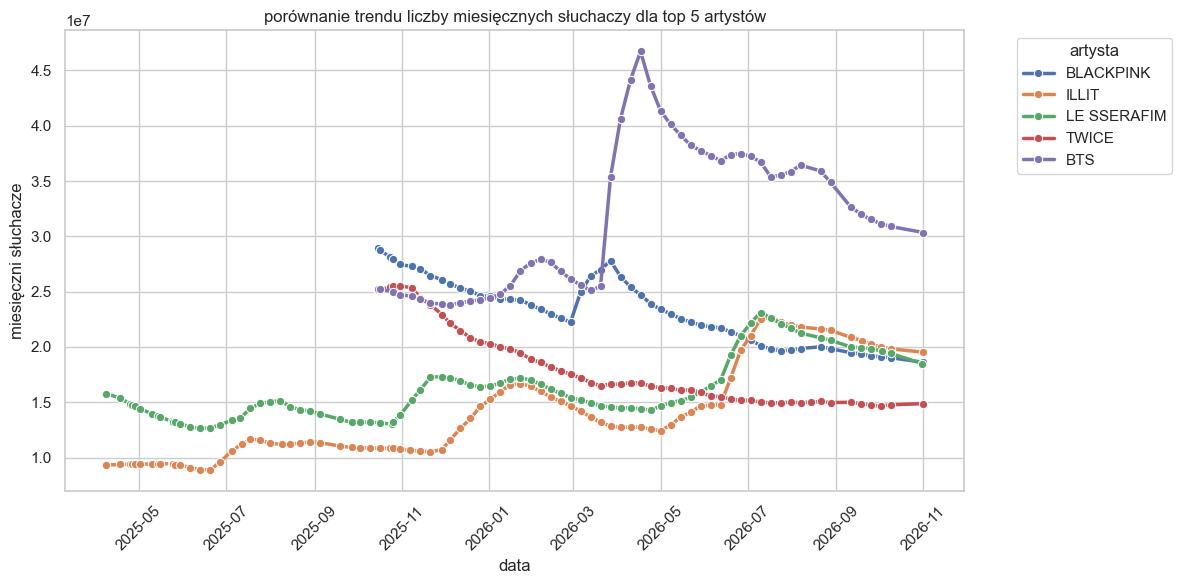

In [10]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_top5, x='period', y='monthly_listeners', hue='group_name', marker='o', linewidth=2.5)
plt.title("porównanie trendu liczby miesięcznych słuchaczy dla top 5 artystów")
plt.xlabel("data")
plt.ylabel("miesięczni słuchacze")
plt.xticks(rotation=45)
plt.legend(title="artysta", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

C:\Users\chlip\AppData\Local\Temp\ipykernel_28392\3392864200.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=peak_listeners, x='monthly_listeners', y='group_name', palette="magma")


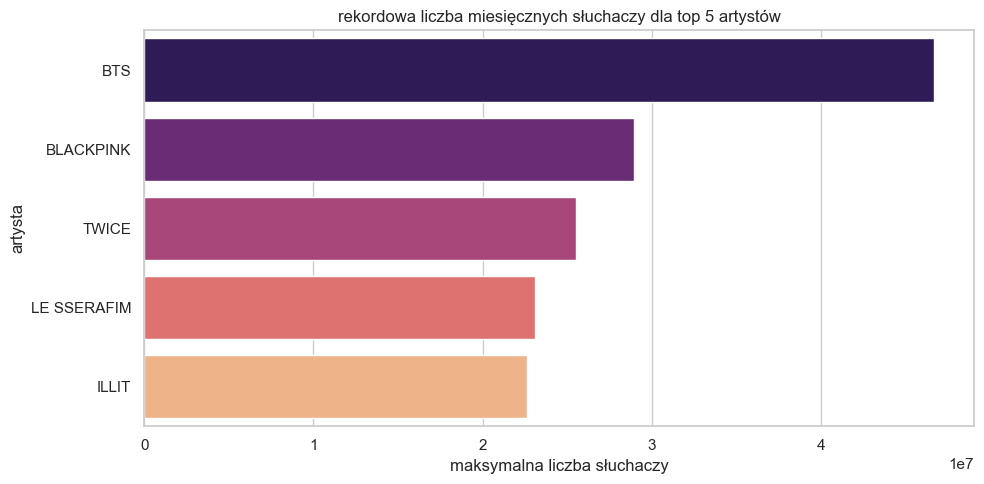

In [11]:
# maksymalna liczba słuchaczy osiągnięta przez każdego z top 5 artystów
peak_listeners = df_top5.groupby('group_name')['monthly_listeners'].max().reset_index()
peak_listeners = peak_listeners.sort_values(by='monthly_listeners', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=peak_listeners, x='monthly_listeners', y='group_name', palette="magma")
plt.title("rekordowa liczba miesięcznych słuchaczy dla top 5 artystów")
plt.xlabel("maksymalna liczba słuchaczy")
plt.ylabel("artysta")
plt.tight_layout()
plt.show()